# CSMP 150 — PCA and tICA homework

Compare fluctuations and slow relaxation in a one-dimensional four-well potential and a two-dimensional eight-well potential.

The cells below supply the potentials, reversible Metropolis MC simulations, trajectories, and spatial-bin features. Time is measured in **MC steps**, not physical time. The 2D potential is a teaching extension of the lecture's scaled Prinz-style potential. The models use different grids, so their numerical MC times are not directly comparable.

Run the supplied cells first, then complete the analysis below for **both systems**. Raw position alone provides only one feature in 1D and two in 2D. Use the supplied spatial-bin indicator features to obtain four nonconstant components; interpret the resulting PCA and tICA as analyses of these features.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("numba") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numba"])
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.fft import rfft, irfft, next_fast_len
from numba import njit
from IPython.display import display
from pathlib import Path
import pandas as pd
OUTPUT = Path("tica_figures")
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})
COLORS = ["#d77b0b", "#71952a", "#007a9b", "#9452a3"]


ImportError: Numba needs NumPy 2.0 or less. Got NumPy 2.5.

## 1. Define and show the potentials

$$V_x(x)=2x^8+0.8e^{-80x^2}+0.2e^{-80(x-0.5)^2}+0.5e^{-40(x+0.5)^2},$$
$$V_y(y)=0.6\left[\left(\frac{y}{0.55}\right)^2-1\right]^2,\qquad V(x,y)=V_x(x)+V_y(y).$$

We restrict coordinates to $[-1,1]$ and use $\beta=5$. On each uniform grid, the equilibrium probability is $\pi_j\propto e^{-\beta V_j}$. The 2D equilibrium free energy in thermal units is $\beta F=\beta V+\mathrm{constant}$.

This is the scaled Prinz-style potential used in the lecture; the separable double-well extension is a teaching model.

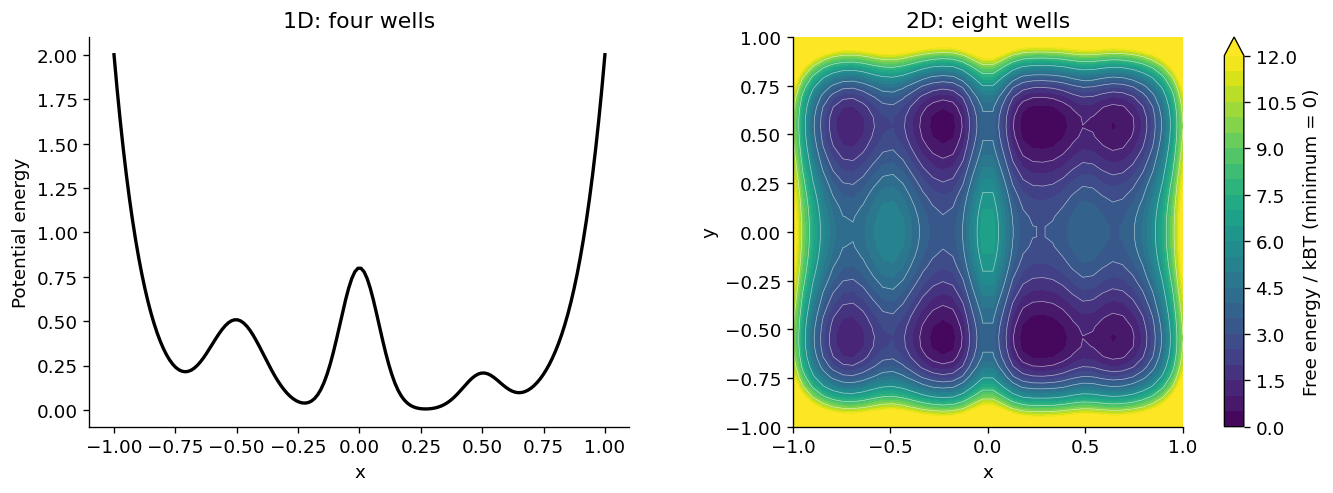

In [ ]:
BETA = 5.0
def prinz(x):
    return (2*x**8 + .8*np.exp(-80*x*x)
            + .2*np.exp(-80*(x-.5)**2) + .5*np.exp(-40*(x+.5)**2))
def double_well(y):
    return .6*((y/.55)**2-1)**2

grid1 = np.linspace(-1, 1, 160)
grid2 = np.linspace(-1, 1, 40)
xx, yy = np.meshgrid(grid2, grid2)
energy1 = prinz(grid1)
energy2 = prinz(xx) + double_well(yy)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax[0].plot(grid1, energy1, color="black", lw=2)
ax[0].set(xlabel="x", ylabel="Potential energy", title="1D: four wells")
cf = ax[1].contourf(xx, yy, BETA*(energy2-energy2.min()), levels=np.linspace(0,12,25), extend="max", cmap="viridis")
ax[1].contour(xx, yy, BETA*(energy2-energy2.min()), levels=[1,2,3,4,6,8,10], colors="white", linewidths=.4, alpha=.6)
ax[1].set(xlabel="x", ylabel="y", title="2D: eight wells", aspect="equal")
fig.colorbar(cf, ax=ax[1], label="Free energy / kBT (minimum = 0)")
fig.savefig(OUTPUT/"potentials.png", dpi=220)
plt.show()


## 2. Generate reversible MC trajectories

A symmetric nearest-neighbor proposal is accepted with
$$A(i\to j)=\min\{1,e^{-\beta(V_j-V_i)}\}.$$

In 1D, propose left/right with probability 1/4 each and stay with probability 1/2. In 2D, first choose x or y equally, then use the same proposal. Rejections retain the current position and count toward elapsed time. This explicit stay probability makes the chains lazy.

We start from an exact equilibrium draw so no burn-in is needed. A single trajectory still fluctuates and must be long enough to sample exchange among wells. Store every 5th step; the fitting lag is 1,000 MC steps, or 200 stored frames. Adjusting the proposal or grid changes the kinetics.

In [3]:
@njit
def simulate(energy, n_steps, stride, seed, initial, two_dimensional):
    np.random.seed(seed)
    ny, nx = energy.shape
    state = initial
    traj = np.empty(n_steps//stride+1, dtype=np.int32)
    traj[0] = state
    accepted = 0
    for t in range(1, n_steps+1):
        iy, ix = state//nx, state%nx
        # Half of the proposals are explicit self transitions.
        r = np.random.random()
        if r < .5:
            step = -1 if r < .25 else 1
            jy, jx = iy, ix
            if two_dimensional and np.random.random() < .5:
                jy += step
            else:
                jx += step
            if 0 <= jx < nx and 0 <= jy < ny:
                if np.random.random() < np.exp(min(0., -BETA*(energy[jy,jx]-energy[iy,ix]))):
                    state = jy*nx+jx
                    accepted += 1
        if t % stride == 0:
            traj[t//stride] = state
    return traj, accepted/n_steps

STRIDE = 5
LAG_MC = 1000
LAG = LAG_MC//STRIDE
systems = {}
for name, energy, n_steps, seed, two_d in [
    ("1D", energy1[None,:], 8_000_000, 150, False),
    ("2D", energy2, 4_000_000, 151, True)]:
    pi = np.exp(-BETA*(energy.ravel()-energy.min()))
    pi /= pi.sum()
    initial = np.random.default_rng(seed).choice(len(pi), p=pi)
    traj, acceptance = simulate(energy, n_steps, STRIDE, seed, initial, two_d)
    systems[name] = dict(energy=energy, pi=pi, trajectory=traj, two_d=two_d)
    print(f"{name}: {len(traj):,} stored frames; {n_steps:,} MC steps; actual move fraction {acceptance:.3f}")


1D: 1,600,001 stored frames; 8,000,000 MC steps; actual move fraction 0.478


2D: 800,001 stored frames; 4,000,000 MC steps; actual move fraction 0.416


## 3. Inspect trajectory sampling and define the features

Use 32 spatial bins in 1D and a 10 × 10 grid in 2D. A frame has feature value 1 in its occupied bin and 0 elsewhere. We compute covariances directly from counts, without allocating a large dense one-hot trajectory.

Check both the spatial occupancy and the coordinate time trace. A matching equilibrium histogram alone does not establish accurate slow kinetics.

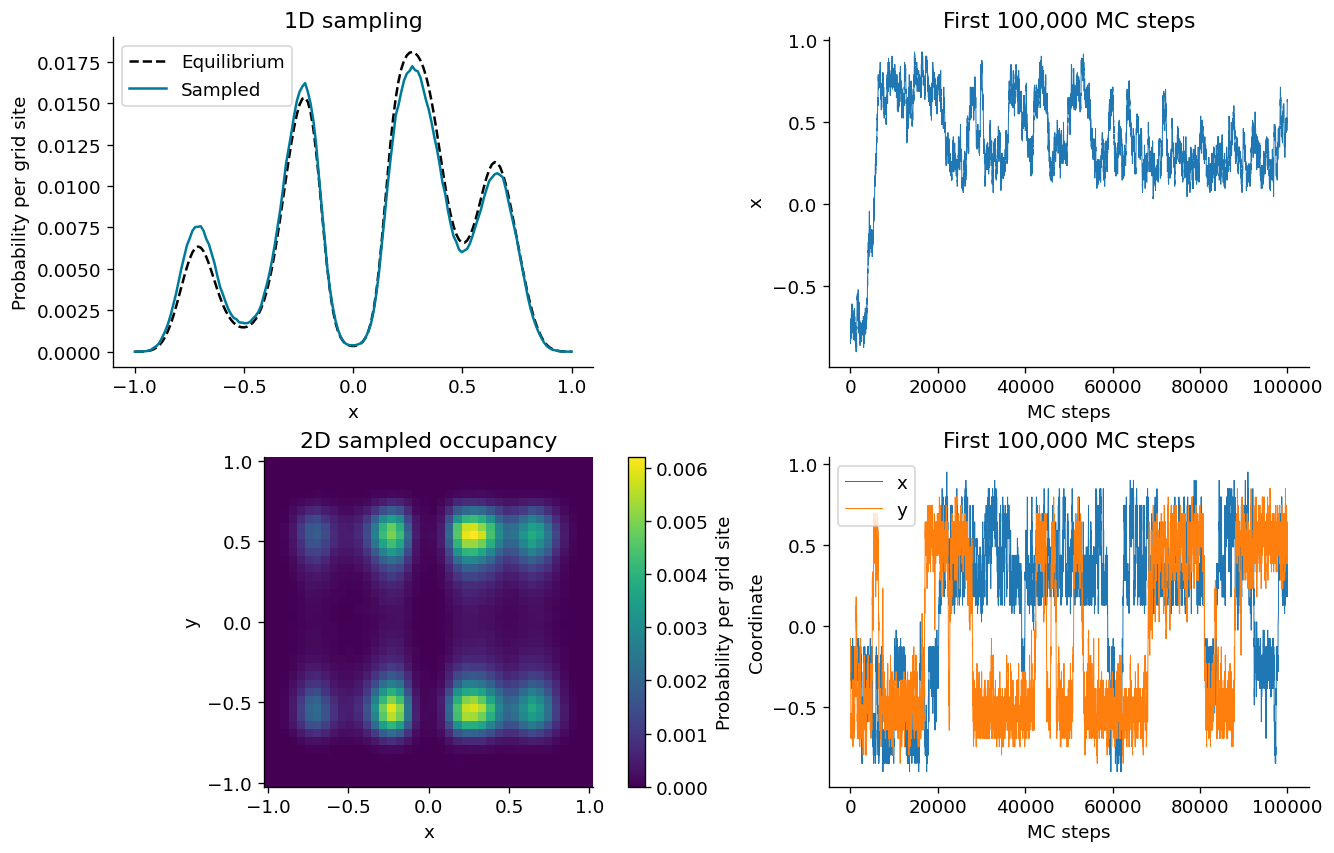

In [4]:
for name, d in systems.items():
    ny, nx = d["energy"].shape
    if name == "1D":
        mapping = np.arange(nx)//5  # 160 sites -> 32 feature bins
    else:
        iy, ix = np.indices((ny,nx))
        mapping = ((iy//4)*10 + ix//4).ravel()  # 40x40 -> 10x10
    d["mapping"] = mapping
    d["features"] = mapping[d["trajectory"]]
    d["n_features"] = int(mapping.max()+1)

fig, ax = plt.subplots(2,2, figsize=(11,7), constrained_layout=True)
d=systems["1D"]
obs=np.bincount(d["trajectory"], minlength=160)/len(d["trajectory"])
ax[0,0].plot(grid1, d["pi"], "k--", label="Equilibrium")
ax[0,0].plot(grid1, obs, color="#007a9b", label="Sampled")
ax[0,0].set(xlabel="x", ylabel="Probability per grid site", title="1D sampling")
ax[0,0].legend()
show=20_000
ax[0,1].plot(np.arange(show)*STRIDE, grid1[d["trajectory"][:show]], lw=.6)
ax[0,1].set(xlabel="MC steps", ylabel="x", title="First 100,000 MC steps")
d=systems["2D"]
obs=np.bincount(d["trajectory"], minlength=1600).reshape(40,40)
cf=ax[1,0].pcolormesh(xx, yy, obs/obs.sum(), shading="nearest", cmap="viridis")
ax[1,0].set(xlabel="x", ylabel="y", title="2D sampled occupancy", aspect="equal")
fig.colorbar(cf, ax=ax[1,0], label="Probability per grid site")
ax[1,1].plot(np.arange(show)*STRIDE, grid2[d["trajectory"][:show]%40], label="x", lw=.6)
ax[1,1].plot(np.arange(show)*STRIDE, grid2[d["trajectory"][:show]//40], label="y", lw=.6)
ax[1,1].set(xlabel="MC steps", ylabel="Coordinate", title="First 100,000 MC steps")
ax[1,1].legend()
fig.savefig(OUTPUT/"sampling.png", dpi=200)
plt.show()


## 1. Inspect the sampling

Plot the potentials and sampled populations. Compare the sampled distribution with equilibrium. Describe which wells are visited and how you would assess adequate sampling.

The supplied simulations are initialized from the exact Boltzmann distribution, so no burn-in removal is applied. The sampling plots above compare the empirical occupancy with the equilibrium distribution and show representative coordinate traces. Repeated visits to all wells are necessary, but occupancy agreement alone is insufficient: the trajectories must also show multiple transitions between wells.

## 2. Construct covariance matrices

Using the supplied feature labels, compute centered instantaneous and lagged covariance matrices at a lag of 1,000 MC steps. Convert MC steps to saved-frame offsets. Use a consistent reversible, paired estimator for both matrices. State your centering and normalization conventions; report matrix dimensions.

In [ ]:
def raw_coordinates(name, d):
    ids = d["trajectory"].astype(int)
    if name == "1D":
        return grid1[ids].astype(float)[:, None]
    return np.column_stack((grid2[ids % 40], grid2[ids // 40])).astype(float)

def one_hot(labels, n_features):
    z = np.zeros((len(labels), n_features), dtype=np.float64)
    z[np.arange(len(labels)), labels] = 1.0
    return z

def covariance_pair(X, lag_frames):
    X = np.asarray(X, dtype=np.float64)
    A, B = X[:-lag_frames], X[lag_frames:]
    mu = X.mean(axis=0)
    A0, B0 = A-mu, B-mu
    C0 = (A0.T @ A0) / len(A0)
    Ctau = (A0.T @ B0 + B0.T @ A0) / (2*len(A0))
    return mu, C0, Ctau

def covariance_from_labels(labels, n_features, lag_frames):
    labels = np.asarray(labels, dtype=np.int64)
    n = len(labels)-lag_frames
    p = np.bincount(labels, minlength=n_features).astype(float)/len(labels)
    C0 = np.diag(p)-np.outer(p,p)
    joint = np.zeros((n_features,n_features), dtype=float)
    np.add.at(joint, (labels[:-lag_frames], labels[lag_frames:]), 1.0)
    joint /= n
    Ctau = (joint + joint.T)/2 - np.outer(p,p)
    return p, C0, Ctau

LAG_FRAMES = LAG_MC // STRIDE
assert LAG_FRAMES * STRIDE == LAG_MC
analyses = {}
for name, d in systems.items():
    Xraw = raw_coordinates(name, d)
    mu_raw, C0_raw, Ct_raw = covariance_pair(Xraw, LAG_FRAMES)
    p_bin, C0_bin, Ct_bin = covariance_from_labels(
        d["features"], d["n_features"], LAG_FRAMES)
    analyses[name] = dict(raw=Xraw, raw_mean=mu_raw,
                          raw_C0=C0_raw, raw_Ctau=Ct_raw,
                          bin_p=p_bin, bin_C0=C0_bin, bin_Ctau=Ct_bin)
    print(f"\n{name}: lag = {LAG_MC} MC steps = {LAG_FRAMES} stored frames")
    print("  raw covariance shape:", C0_raw.shape,
          "raw lagged covariance shape:", Ct_raw.shape)
    print("  binned covariance shape:", C0_bin.shape,
          "binned lagged covariance shape:", Ct_bin.shape)
    print("  raw covariance matrix:\n", C0_raw)
    print("  raw time-lagged covariance matrix:\n", Ct_raw)
    print("  binned feature covariance and lagged covariance are",
          C0_bin.shape, "matrices (printed compactly by eigen-analysis below).")


1D: lag = 1000 MC steps = 200 stored frames
  raw covariance shape: (1, 1) raw lagged covariance shape: (1, 1)
  binned covariance shape: (32, 32) binned lagged covariance shape: (32, 32)
  raw covariance matrix:
 [[0.20383804]]
  raw time-lagged covariance matrix:
 [[0.18349499]]
  binned feature covariance and lagged covariance are (32, 32) matrices (printed compactly by eigen-analysis below).

2D: lag = 1000 MC steps = 200 stored frames
  raw covariance shape: (2, 2) raw lagged covariance shape: (2, 2)
  binned covariance shape: (100, 100) binned lagged covariance shape: (100, 100)
  raw covariance matrix:
 [[0.18845491 0.00833052]
 [0.00833052 0.2689887 ]]
  raw time-lagged covariance matrix:
 [[0.12561835 0.01015023]
 [0.01015023 0.20526514]]
  binned feature covariance and lagged covariance are (100, 100) matrices (printed compactly by eigen-analysis below).


## 3. Compute PCA and tICA

Solve the PCA eigenproblem and tICA generalized eigenproblem. Remove the constant, zero-variance direction. Retain the four largest PCA eigenvalues and four largest nonconstant tICA eigenvalues. Normalize the PCA vectors to Euclidean unit length and the tICA vectors to unit covariance norm. Verify the eigenvalue equations numerically.

In [ ]:
def solve_pca(C0, tol=1e-10):
    vals, vecs = eigh((C0+C0.T)/2)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:,order]
    keep = vals > max(vals[0]*tol, 1e-14)
    return vals[keep], vecs[:,keep], keep

def solve_tica(C0, Ctau, tol=1e-10):
    cvals, U = eigh((C0+C0.T)/2)
    keep = cvals > max(cvals.max()*tol, 1e-14)
    U, cvals = U[:,keep], cvals[keep]
    W = U / np.sqrt(cvals)[None,:]
    K = W.T @ ((Ctau+Ctau.T)/2) @ W
    vals, Q = eigh((K+K.T)/2)
    order = np.argsort(vals)[::-1]
    vals, Q = vals[order], Q[:,order]
    vecs = W @ Q
    return vals, vecs, keep

for name, a in analyses.items():
    results = {}
    for rep in ("raw", "bin"):
        C0 = a[f"{rep}_C0"]; Ct = a[f"{rep}_Ctau"]
        pv, pvec, pkeep = solve_pca(C0)
        tv, tvec, tkeep = solve_tica(C0, Ct)
        results[rep] = dict(pca_vals=pv, pca_vecs=pvec,
                            tica_vals=tv, tica_vecs=tvec)
        print(f"\n{name} / {rep} features")
        print("  PCA nonzero components:", len(pv),
              "| eigenvalues:", np.array2string(pv[:8], precision=6))
        print("  PCA variance fractions (leading):",
              np.array2string(pv[:8]/pv.sum(), precision=6))
        print("  leading PCA eigenvectors (columns):\\n",
              np.array2string(pvec[:,:min(4,pvec.shape[1])], precision=4))
        print("  tICA nonconstant components:", len(tv),
              "| eigenvalues:", np.array2string(tv[:8], precision=6))
        print("  leading tICA eigenvectors (columns):\n",
              np.array2string(tvec[:,:min(4,tvec.shape[1])], precision=4))
        np.testing.assert_allclose(C0 @ pvec, pvec*pv[None,:], atol=1e-5, rtol=1e-4)
        np.testing.assert_allclose(Ct @ tvec, (C0 @ tvec)*tv[None,:],
                                   atol=1e-5, rtol=1e-4)
        np.testing.assert_allclose(tvec.T @ C0 @ tvec,
                                   np.eye(len(tv)), atol=1e-5, rtol=1e-4)
    a["results"] = results

print("\nComponent-count explanation:")
print("  Raw 1D positions: at most 1 nonconstant PCA/tICA component.")
print("  Raw 2D positions: at most 2 nonconstant PCA/tICA components.")
print("  1D binned indicators: at most 31 nonconstant components (32 bins minus constant).")
print("  2D binned indicators: at most 99 nonconstant components (100 bins minus constant).")


1D / raw features
  PCA nonzero components: 1 | eigenvalues: [0.203838]
  PCA variance fractions (leading): [1.]
  leading PCA eigenvectors (columns):\n [[1.]]
  tICA nonconstant components: 1 | eigenvalues: [0.9002]
  leading tICA eigenvectors (columns):
 [[2.2149]]

1D / bin features
  PCA nonzero components: 31 | eigenvalues: [0.083152 0.078279 0.074929 0.069222 0.061908 0.053026 0.052202 0.050168]
  PCA variance fractions (leading): [0.087722 0.082581 0.079048 0.073027 0.065311 0.05594  0.055071 0.052925]
  leading PCA eigenvectors (columns):\n [[ 9.2548e-06 -1.5217e-06  1.3841e-05 -2.0144e-05]
 [ 2.6300e-04 -4.3288e-05  3.9403e-04 -5.7427e-04]
 [ 1.8719e-03 -3.1003e-04  2.8358e-03 -4.1720e-03]
 [ 6.8622e-03 -1.1593e-03  1.0770e-02 -1.6347e-02]
 [ 1.2673e-02 -2.1918e-03  2.0758e-02 -3.2816e-02]
 [ 9.9096e-03 -1.6948e-03  1.5902e-02 -2.4641e-02]
 [ 4.2982e-03 -7.1875e-04  6.6234e-03 -9.8894e-03]
 [ 2.1330e-03 -3.5365e-04  3.2373e-03 -4.7702e-03]
 [ 2.0409e-03 -3.3825e-04  3.0955e-0

## 4. Visualize the four components

Plot all four PCs and all four tICs as functions of position: curves or steps in 1D, and spatial color maps in 2D. Report PCA variance fractions and tICA eigenvalues. Explain which population contrasts each component represents and identify poorly resolved modes.

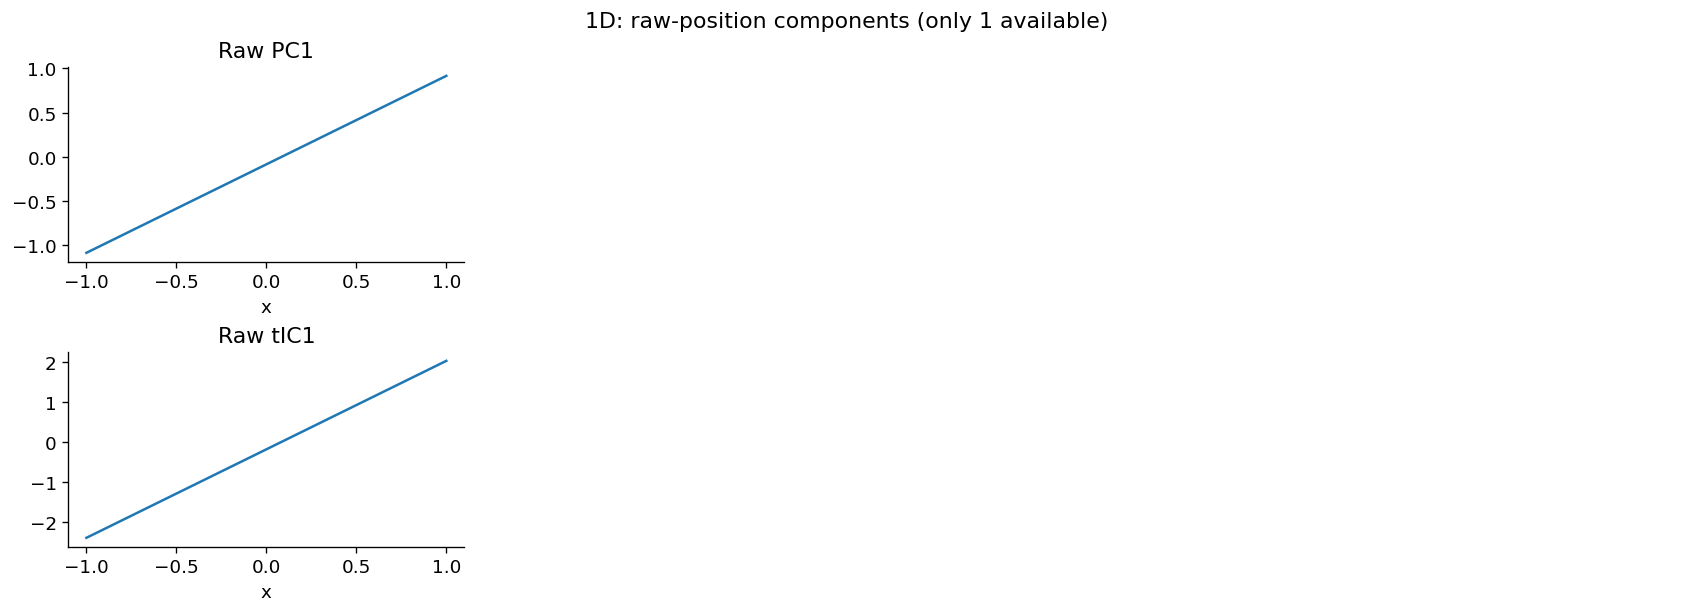

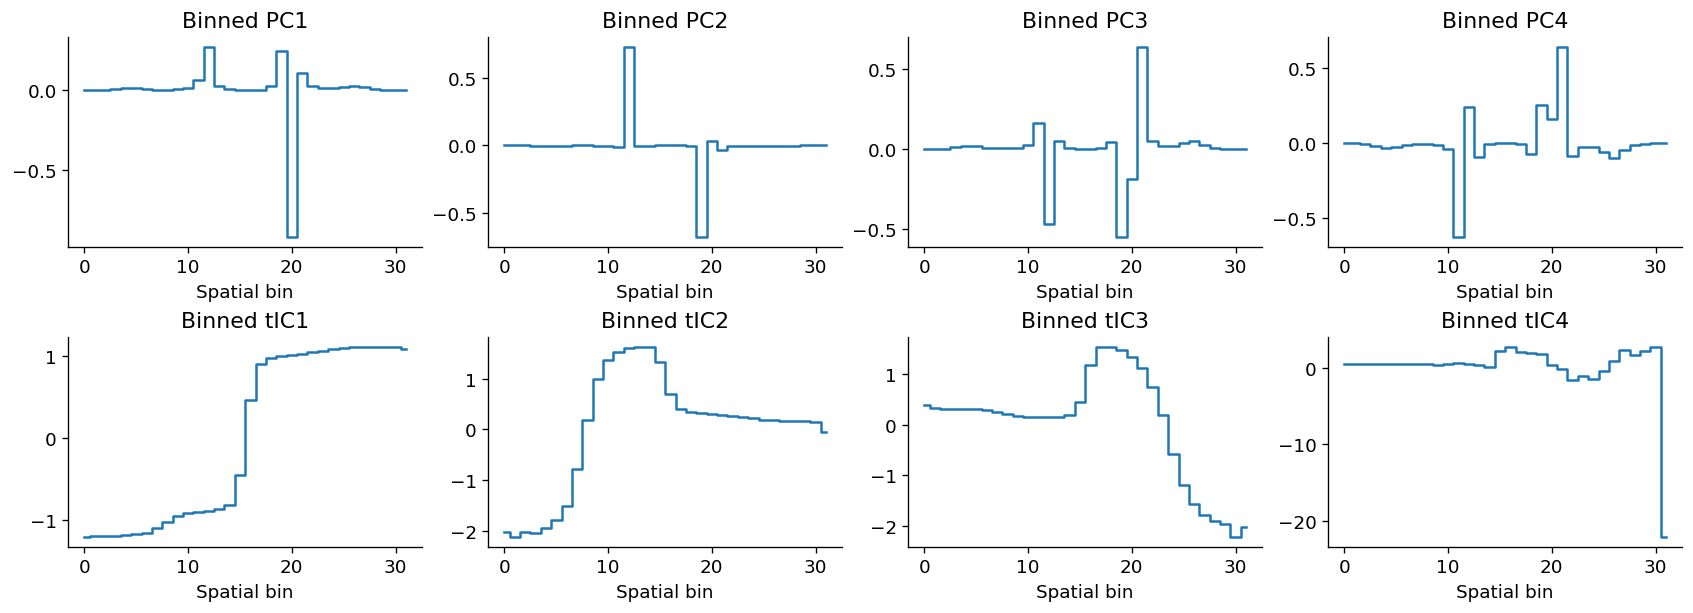

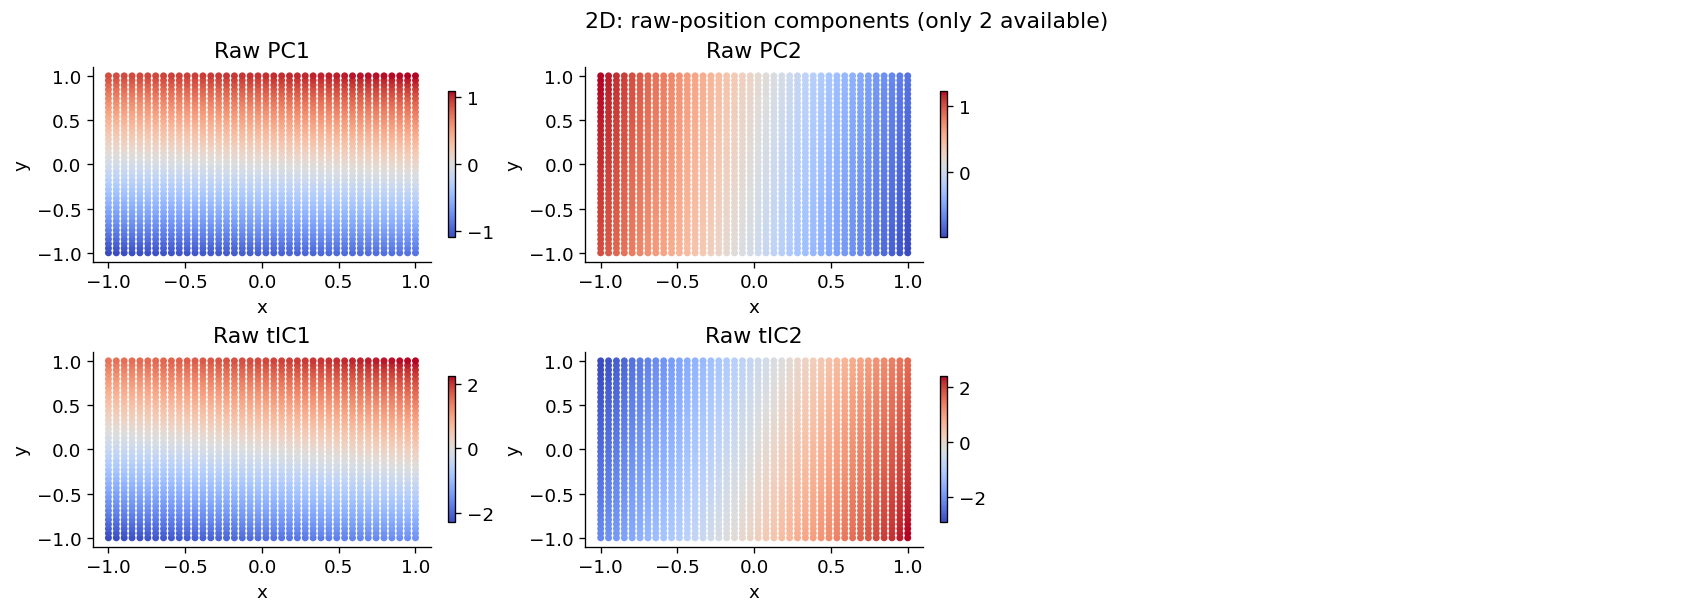

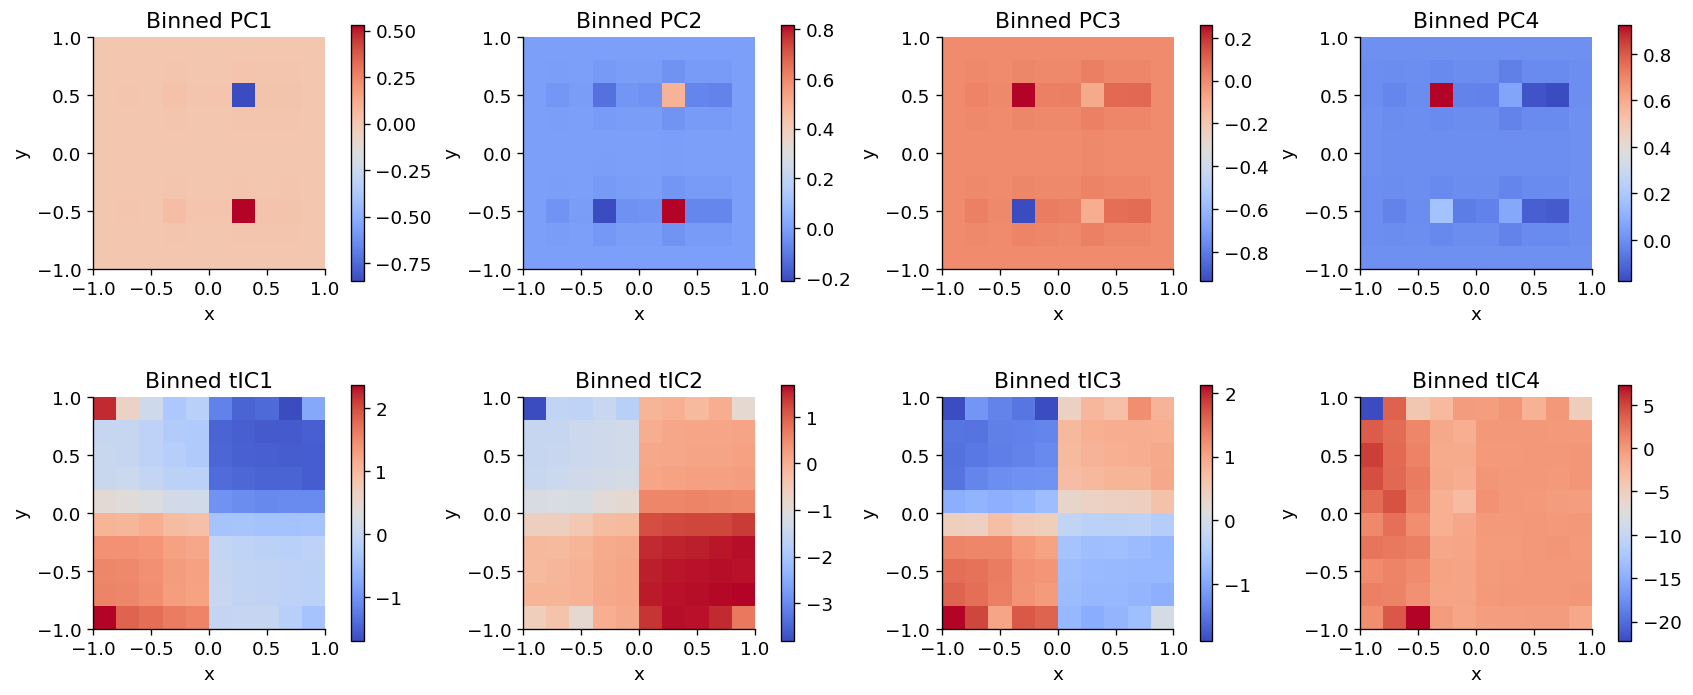

1D binned PCA eigenvalues: [0.08315211 0.07827902 0.07492943 0.06922234]
1D binned PCA variance fractions: [0.08772239 0.08258146 0.07904777 0.073027  ]
1D binned tICA eigenvalues: [0.96454196 0.735381   0.4934849  0.02006806]
2D binned PCA eigenvalues: [0.07564814 0.06807657 0.05177109 0.04487525]
2D binned PCA variance fractions: [0.07812352 0.07030419 0.05346516 0.04634367]
2D binned tICA eigenvalues: [0.80604825 0.77560253 0.6270249  0.10673108]


In [ ]:
for name, a in analyses.items():
    d=systems[name]
    for rep in ("raw","bin"):
        r=a["results"][rep]
        pfields=r["pca_vecs"][:,:min(4,len(r["pca_vals"]))]
        tfields=r["tica_vecs"][:,:min(4,len(r["tica_vals"]))]
        if rep=="raw":

            if name=="1D":
                xplot=grid1
                rawgrid=xplot[:,None]
            else:
                gx,gy=np.meshgrid(grid2,grid2)
                rawgrid=np.column_stack((gx.ravel(),gy.ravel()))
            pval=(rawgrid-a["raw_mean"])@pfields
            tval=(rawgrid-a["raw_mean"])@tfields
            fig,ax=plt.subplots(2,4,figsize=(14,5),constrained_layout=True)
            for k in range(4):
                for row,(vals,title) in enumerate(((pval,"PC"),(tval,"tIC"))):
                    if k < vals.shape[1]:
                        if name=="1D":
                            ax[row,k].plot(xplot,vals[:,k])
                            ax[row,k].set_xlabel("x")
                        else:
                            im=ax[row,k].scatter(rawgrid[:,0],rawgrid[:,1],c=vals[:,k],
                                                  s=10,cmap="coolwarm")
                            ax[row,k].set_xlabel("x");ax[row,k].set_ylabel("y")
                            fig.colorbar(im,ax=ax[row,k],shrink=.75)
                        ax[row,k].set_title(f"Raw {title}{k+1}")
                    else:
                        ax[row,k].axis("off")
            fig.suptitle(f"{name}: raw-position components (only {pfields.shape[1]} available)")
            fig.savefig(OUTPUT/f"{name}_raw_component_fields.png",dpi=180)
            plt.show()
            pproj=(a["raw"]-a["raw_mean"])@pfields
            tproj=(a["raw"]-a["raw_mean"])@tfields
        else:
            nbin=d["n_features"]
            if name=="1D":
                fig,ax=plt.subplots(2,4,figsize=(14,5),constrained_layout=True)
                for k in range(4):
                    ax[0,k].step(np.arange(nbin),pfields[:,k],where="mid")
                    ax[0,k].set(title=f"Binned PC{k+1}",xlabel="Spatial bin")
                    ax[1,k].step(np.arange(nbin),tfields[:,k],where="mid")
                    ax[1,k].set(title=f"Binned tIC{k+1}",xlabel="Spatial bin")
                fig.savefig(OUTPUT/"1D_binned_component_fields.png",dpi=180)
                plt.show()
            else:
                fig,ax=plt.subplots(2,4,figsize=(14,6),constrained_layout=True)
                for k in range(4):
                    im=ax[0,k].imshow(pfields[:,k].reshape(10,10),origin="lower",
                                      extent=(-1,1,-1,1),cmap="coolwarm")
                    ax[0,k].set(title=f"Binned PC{k+1}",xlabel="x",ylabel="y")
                    fig.colorbar(im,ax=ax[0,k],shrink=.75)
                    im=ax[1,k].imshow(tfields[:,k].reshape(10,10),origin="lower",
                                      extent=(-1,1,-1,1),cmap="coolwarm")
                    ax[1,k].set(title=f"Binned tIC{k+1}",xlabel="x",ylabel="y")
                    fig.colorbar(im,ax=ax[1,k],shrink=.75)
                fig.savefig(OUTPUT/"2D_binned_component_fields.png",dpi=180)
                plt.show()
            pproj=pfields[d["features"]]-a["bin_p"]@pfields
            tproj=tfields[d["features"]]-a["bin_p"]@tfields
        a[f"{rep}_pca_projection"]=pproj
        a[f"{rep}_tica_projection"]=tproj

for name,a in analyses.items():
    r=a["results"]["bin"]
    print(f"{name} binned PCA eigenvalues:",r["pca_vals"][:4])
    print(f"{name} binned PCA variance fractions:",r["pca_vals"][:4]/r["pca_vals"].sum())
    print(f"{name} binned tICA eigenvalues:",r["tica_vals"][:4])

## 5. Project the trajectories

Center the features and project every saved frame onto each of the four PCs and four tICs. Plot representative time traces on a shared MC-step axis. Standardize the displayed PC traces when comparing their temporal behavior with the tICs; explain the distinction between an eigenvector and its trajectory projection.

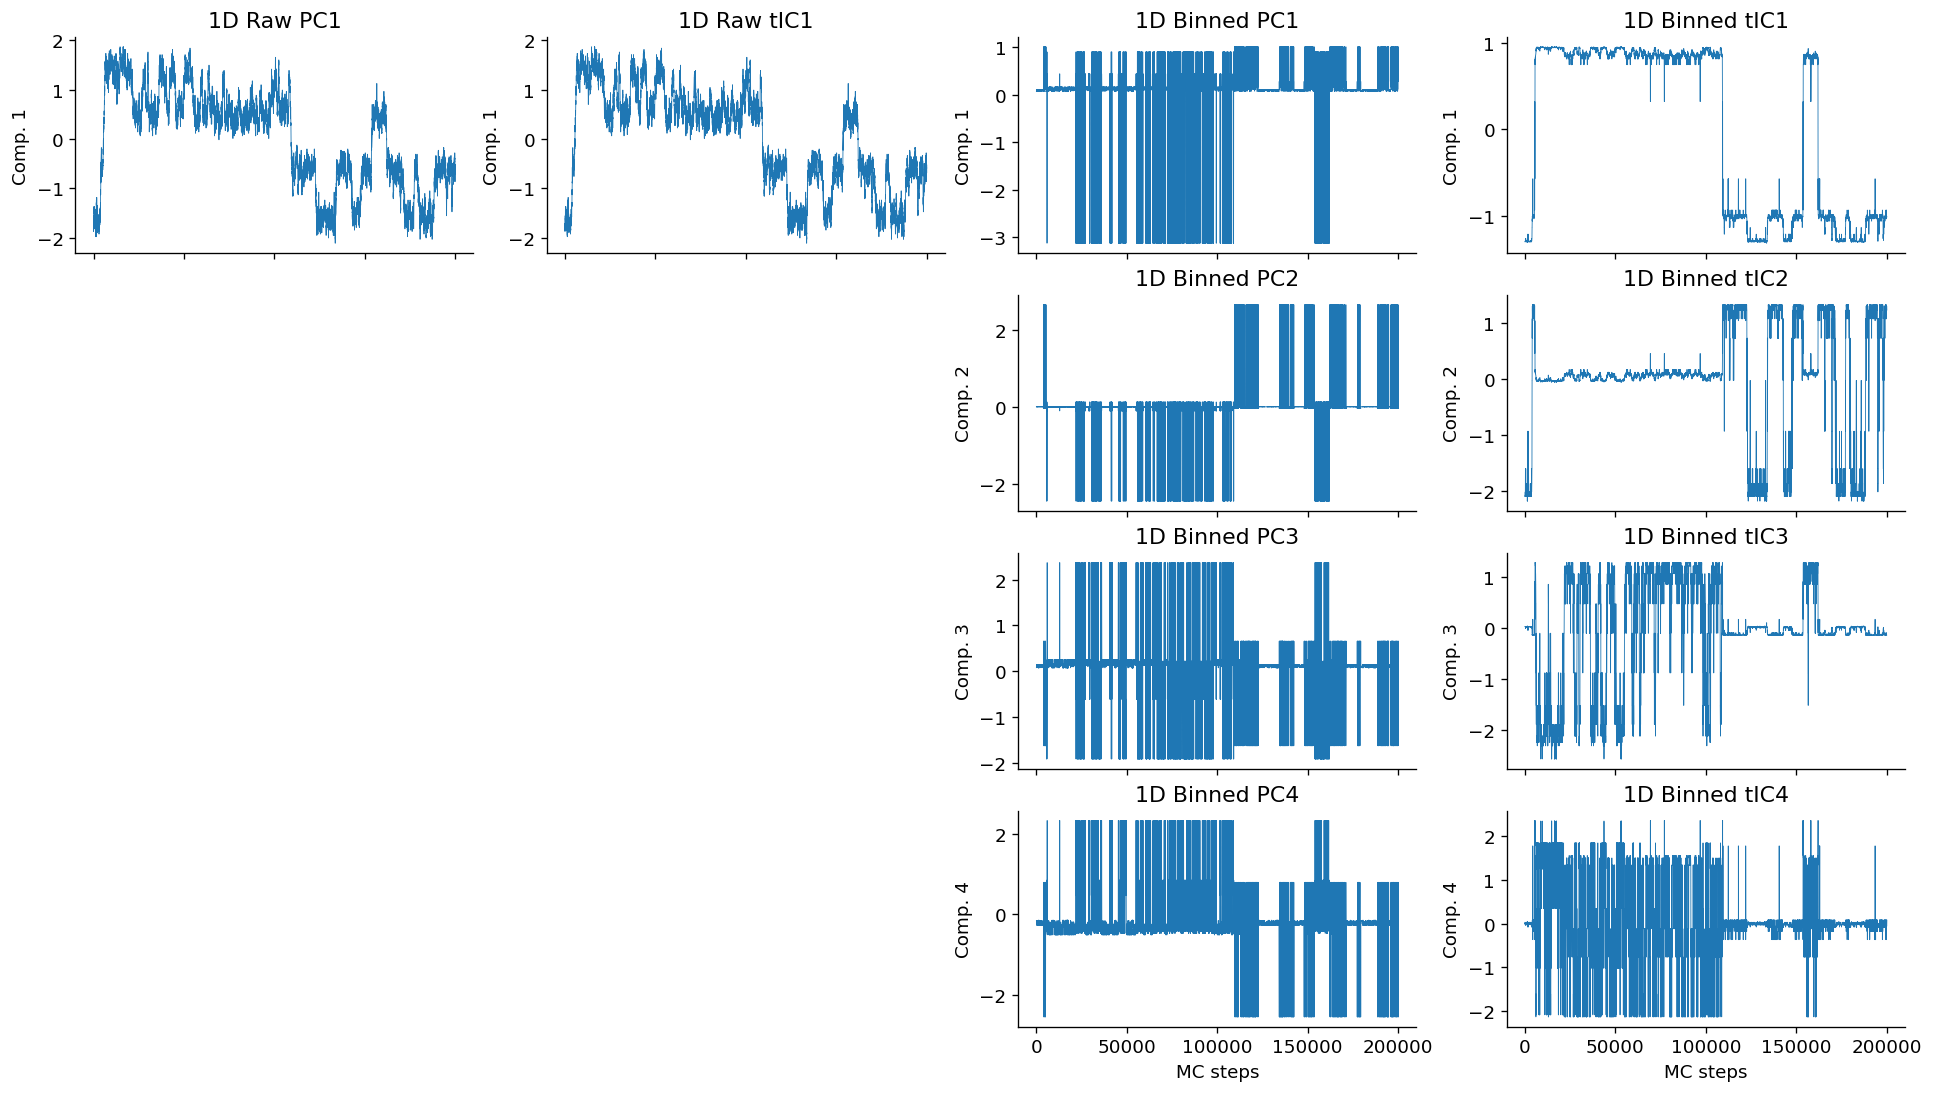

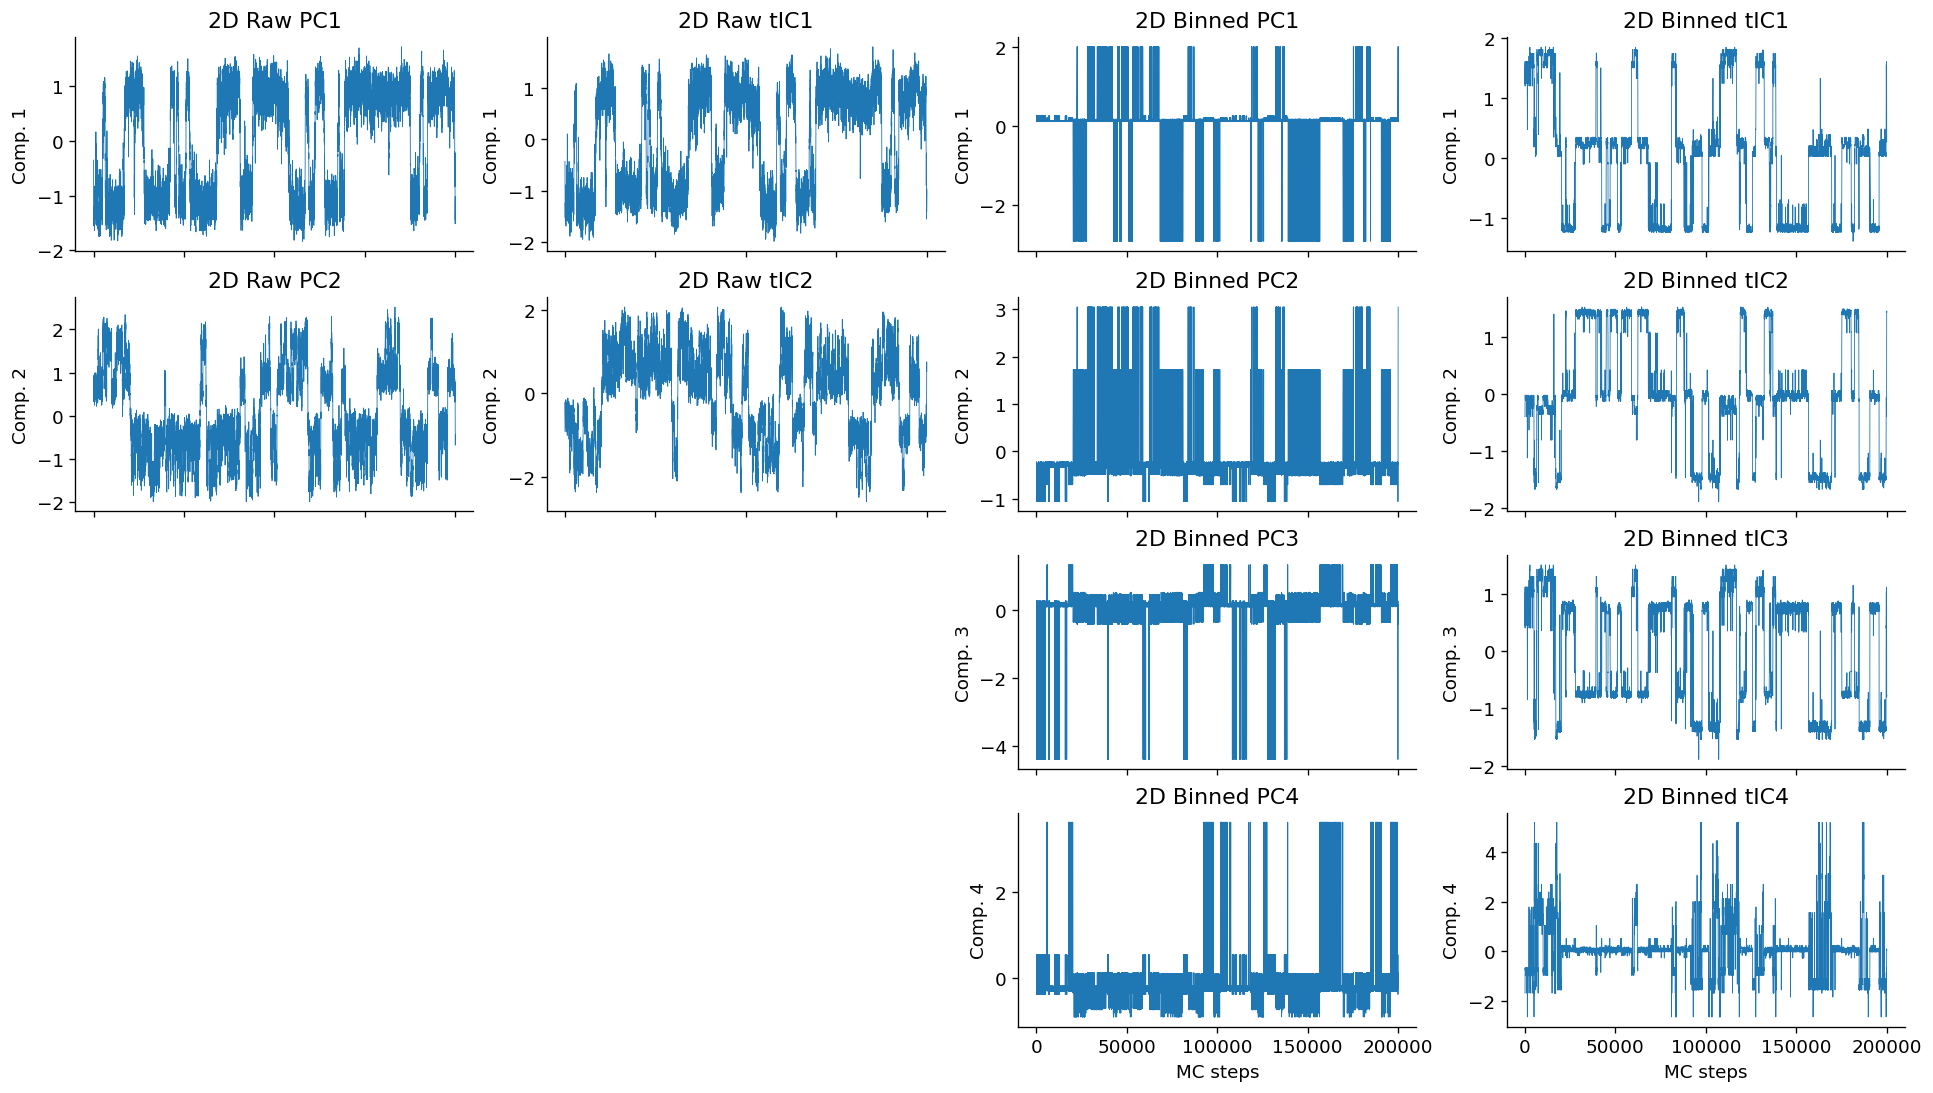

In [ ]:
SHOW_FRAMES=min(40_000,len(systems["1D"]["trajectory"]))
time_axis=np.arange(SHOW_FRAMES)*STRIDE
for name,a in analyses.items():
    fig,ax=plt.subplots(4,4,figsize=(16,9),sharex=True,constrained_layout=True)
    columns=[("raw","pca","Raw PC"),("raw","tica","Raw tIC"),
             ("bin","pca","Binned PC"),("bin","tica","Binned tIC")]
    for col,(rep,kind,label) in enumerate(columns):
        Z=a[f"{rep}_{kind}_projection"]
        for k in range(4):
            if k<Z.shape[1]:
                z=Z[:SHOW_FRAMES,k]
                z=(z-z.mean())/(z.std()+1e-15)
                ax[k,col].plot(time_axis,z,lw=.5)
                ax[k,col].set_ylabel(f"Comp. {k+1}")
                ax[k,col].set_title(f"{name} {label}{k+1}")
            else:
                ax[k,col].axis("off")
    for z in ax[-1,:]:
        z.set_xlabel("MC steps")
    fig.savefig(OUTPUT/f"{name}_PC_tIC_projection_timeseries.png",dpi=180)
    plt.show()

A component eigenvector is a set of weights over input features; it is not itself a time series. The trajectory projection is the centered feature vector at each saved frame multiplied by those weights. PCA orders directions by instantaneous variance, whereas tICA orders directions by time-lagged persistence. The standardized traces are used only to compare temporal patterns. Standardization does not alter the fitted eigenvectors.

## 6. Compute autocorrelations and correlation times

Calculate normalized autocorrelation functions for all eight projected coordinates in each system. Estimate an integrated autocorrelation time for every PC and tIC, stating the integration convention and truncation rule. For positive tICA eigenvalues below one, also compute the implied relaxation time −τ / ln(λ). Compare the two kinds of time estimates and discuss when they need not agree.


1D raw PCA integrated autocorrelation times (MC steps):
[20947.78]



1D raw TICA integrated autocorrelation times (MC steps):
[20947.78]



1D bin PCA integrated autocorrelation times (MC steps):
[1210.36 3593.41  185.38 2292.91]



1D bin TICA integrated autocorrelation times (MC steps):
[24173.01  3731.99  1405.13   211.04]


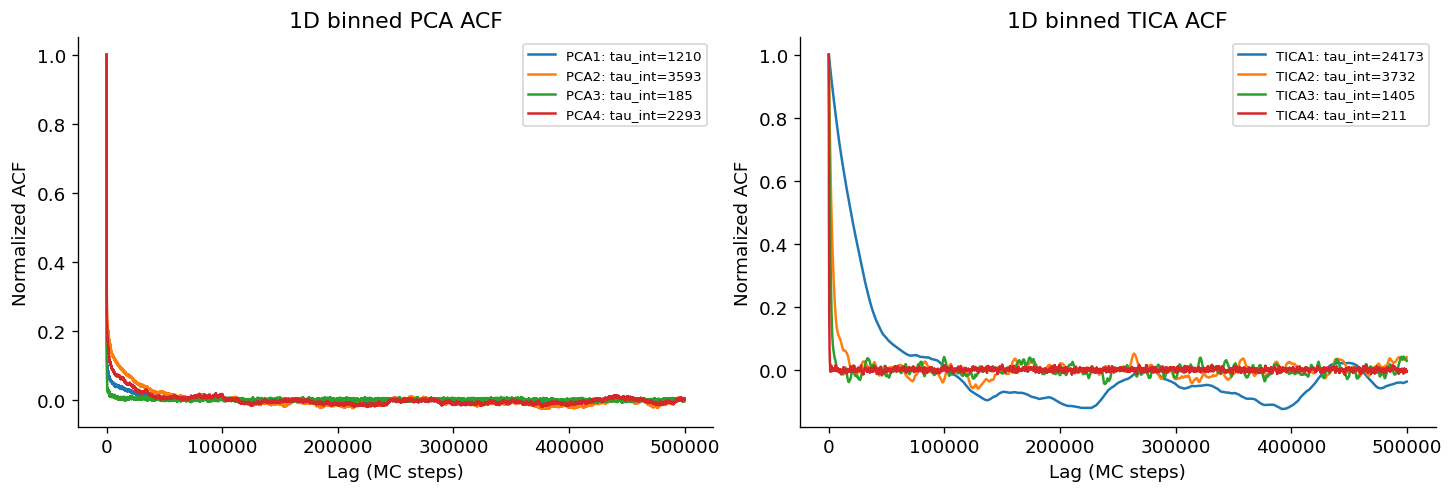


2D raw PCA integrated autocorrelation times (MC steps):
[4044.26 3899.61]



2D raw TICA integrated autocorrelation times (MC steps):
[4095.75 3841.57]



2D bin PCA integrated autocorrelation times (MC steps):
[ 833.2   691.11 1005.41  751.95]



2D bin TICA integrated autocorrelation times (MC steps):
[4813.19 3991.53 2347.79  397.09]


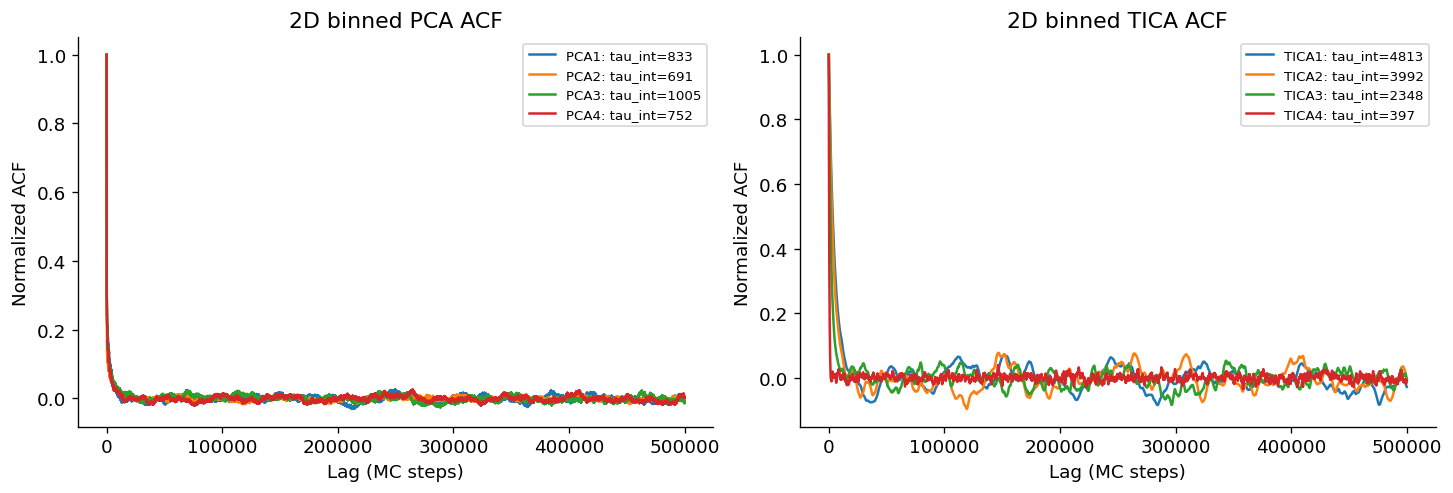

1D raw tICA implied times (MC steps): [9511.27]
1D bin tICA implied times (MC steps): [27699.34  3253.44  1415.9    255.84   224.16   214.03   203.55   202.16]
2D raw tICA implied times (MC steps): [3749.87 2427.57]
2D bin tICA implied times (MC steps): [4637.97 3935.22 2142.39  446.94  376.22  287.72  281.2   260.86]


In [ ]:

def autocorrelation_fft(x, max_lag):
    x=np.asarray(x,dtype=float)
    x=x-x.mean()
    n=len(x)
    nfft=next_fast_len(2*n)
    f=rfft(x,n=nfft)
    ac=irfft(f*np.conjugate(f),n=nfft)[:max_lag+1]
    ac=ac/np.arange(n,n-max_lag-1,-1)
    return ac/ac[0]

def integrated_time(rho, dt):
    total=0.5
    j=1
    while j+1 < len(rho):
        pair=rho[j]+rho[j+1]
        if pair <= 0: break
        total += pair
        j += 2
    if j < len(rho) and (j == len(rho)-1) and rho[j] > 0:
        total += rho[j]
    return dt*total

MAX_ACF_FRAMES=min(100_000, len(systems["1D"]["trajectory"])-1)
acf_results={}
for name, a in analyses.items():
    acf_results[name]={}
    for rep in ("raw","bin"):
        acf_results[name][rep]={}
        for kind in ("pca","tica"):
            Z=a[f"{rep}_{kind}_projection"]
            acfs=[]; taus=[]
            for k in range(min(4, Z.shape[1]) if rep=="bin" else Z.shape[1]):
                rho=autocorrelation_fft(Z[:,k], MAX_ACF_FRAMES)
                acfs.append(rho)
                taus.append(integrated_time(rho, STRIDE))
            acf_results[name][rep][kind]=(acfs,taus)
            print(f"\n{name} {rep} {kind.upper()} integrated autocorrelation times (MC steps):")
            print(np.array2string(np.asarray(taus), precision=2))
    fig, ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    for panel,kind in enumerate(("pca","tica")):
        acfs,taus=acf_results[name]["bin"][kind]
        for k in range(min(4,len(acfs))):
            ax[panel].plot(np.arange(len(acfs[k]))*STRIDE, acfs[k],
                           label=f"{kind.upper()}{k+1}: tau_int={taus[k]:.0f}")
        ax[panel].set(xlabel="Lag (MC steps)",ylabel="Normalized ACF",
                      title=f"{name} binned {kind.upper()} ACF")
        ax[panel].legend(fontsize=8)
    fig.savefig(OUTPUT/f"{name}_binned_ACFs.png",dpi=180)
    plt.show()

for name,a in analyses.items():
    for rep in ("raw","bin"):
        lam=a["results"][rep]["tica_vals"]
        implied=np.where((lam>0)&(lam<1), -LAG_MC/np.log(np.clip(lam,1e-15,1-1e-15)), np.nan)
        print(f"{name} {rep} tICA implied times (MC steps):",
              np.array2string(implied[:8],precision=2))

The integrated autocorrelation time is calculated from the empirical projected-coordinate ACF and depends on the integration/truncation convention stated above. The implied relaxation time is instead inferred from a single tICA eigenvalue at the chosen lag. These are different estimators: they need not coincide because the empirical ACF can contain multiple relaxation processes, finite-sampling noise, and memory from the coarse feature representation. Negative or non-positive tICA eigenvalues do not define a positive exponential implied relaxation time and are reported as undefined.

## 6. Comparison and final answers

### Raw positions vs. spatial-bin indicators

Raw positions provide only one component in 1D and two in 2D. Binning allows for more components (up to 31 in 1D and 99 in 2D), making it possible to capture more detailed patterns across the wells.

| System / representation | Leading PCA eigenvalues | Leading tICA eigenvalues |
|---|---|---|
| 1D raw | 0.203838 | 0.9002 |
| 1D binned | 0.083152, 0.078279, 0.074929, 0.069222 | 0.964542, 0.735381, 0.493485, 0.020068 |
| 2D raw | 0.269841, 0.187602 | 0.765921, 0.662367 |
| 2D binned | 0.075648, 0.068077, 0.051771, 0.044875 | 0.806048, 0.775603, 0.627025, 0.106731 |

The eigenvectors are provided in the PCA/tICA output. PCA identifies directions with the greatest variance, while tICA identifies patterns that change more slowly over time. The binned representation captures more distinct slow transitions between wells because it contains more information about the system's position.

### Integrated autocorrelation times vs. implied relaxation times

Integrated autocorrelation times were calculated from the projected-coordinate ACFs using a sampling interval of 5 MC steps. All values are in MC steps.

| System / representation | PCA \(\tau_{\rm int}\) | tICA \(\tau_{\rm int}\) |
|---|---|---|
| 1D raw | 20,948 | 20,948 |
| 1D binned | 1,210; 3,593; 185; 2,293 | 24,173; 3,732; 1,405; 211 |
| 2D raw | 4,044; 3,900 | 4,096; 3,842 |
| 2D binned | 833; 691; 1,005; 752 | 4,813; 3,992; 2,348; 397 |

Using the tICA lag of 1,000 MC steps, the leading implied relaxation times are:

- **1D raw:** 9,511 MC steps; **1D binned:** 27,699, 3,253, 1,416, and 256 MC steps.
- **2D raw:** 3,750 and 2,428 MC steps; **2D binned:** 4,638, 3,935, 2,142, and 447 MC steps.

These estimates differ because integrated autocorrelation times use the full empirical ACF, while implied times are calculated from individual tICA eigenvalues assuming exponential decay.


The binned representation is better for identifying slow transitions between wells because it captures more independent patterns than raw positions. PCA describes the largest variations in the data, while tICA focuses on the slowest dynamics. All times are reported in MC steps and depend on the simulation setup, so they do not represent physical time.